https://github.com/madhel310/Deliverable_1

In [4]:
from datetime import datetime
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import requests
import yaml


Task 1: Temperature
First request the daily mean air temperture for all of 2025.
The specifications you will need for this is:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
 'sources': 'SN17850',
 'elements': 'mean(air_temperature P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}
Otherwise you can follow the example from frost.met.no on how to get the data
when using Python
Make a nicely formatted plot of this air temperature, where time is on the x-axis and
temperature is on the y-axis
Create a nicely formatted summary table containing mean, median, min and max
temperature for this year, and display it with print()

Data er hentet fra frost.met.no!

Sammendrag for 2025:
  Statistikk  Temperatur (°C)
0       Mean              7.9
1     Median              8.4
2        Min            -15.5
3        Max             23.7


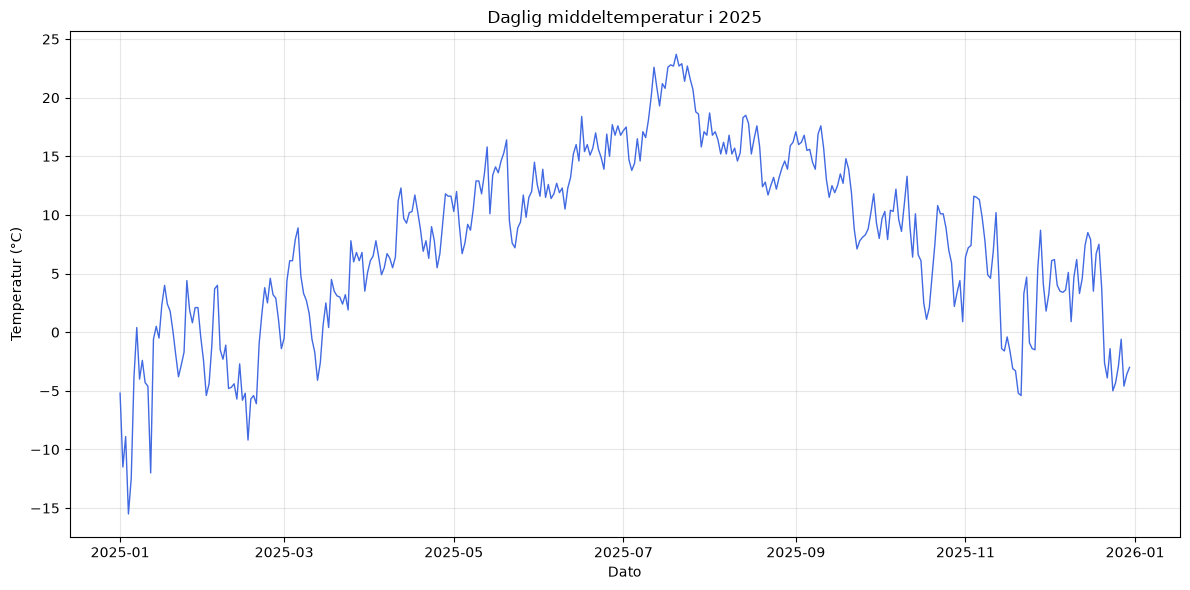

In [5]:



#Henter klient  ID
with open("client_id.txt", "r") as f:
    client_id = f.read().strip()


endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

#HTTP request
r = requests.get(
    endpoint,
    params = parameters, 
    auth=(client_id, '')
)

#Henter JSON data
json = r.json()

if r.status_code == 200:
    
    print('Data er hentet fra frost.met.no!')

    data =json['data']

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])

        row['referenceTime'] = item['referenceTime']
        row['sourceId'] = item['sourceId']

        rows.append(row)

    df = pd.concat(rows, ignore_index=True)
    df = df[df['timeOffset'] == 'PT0H']
else:

    print(f"Feil! Returnerte statuskode {r.status_code}")
    print(json['error']['message'])
    raise SystemExit("Stopper fordi data ikke ble hentet")

df['referenceTime'] = pd.to_datetime(df['referenceTime'])

temps = df['value']


summary = pd.DataFrame({
    'Statistikk': ['Mean', 'Median', 'Min', 'Max'],
    'Temperatur (°C)': [
        temps.mean(),
        temps.median(),
        temps.min(),
        temps.max()
    ]
})

print("\nSammendrag for 2025:")
print(summary.round(2))

plt.figure(figsize=(12, 6))

plt.plot(
    df['referenceTime'],
    temps,
    color='royalblue',
    linewidth=1
)

plt.title('Daglig middeltemperatur i 2025')
plt.xlabel('Dato')
plt.ylabel('Temperatur (°C)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Task 2: Precipitation
Request data for precipitation for the same time period, specifically measurements
of precipitation over 24 hours. This is coded as sum(precipitation_amount
P1D) in the database
Create a new plot that shows both the temperature from task 1 and the precipitation
in the same plot
Think through how to display both values in a way that is useful and looks good
Consider which type of plot works best for each measurement (scatter, line, bar,
pie chart, ...?)


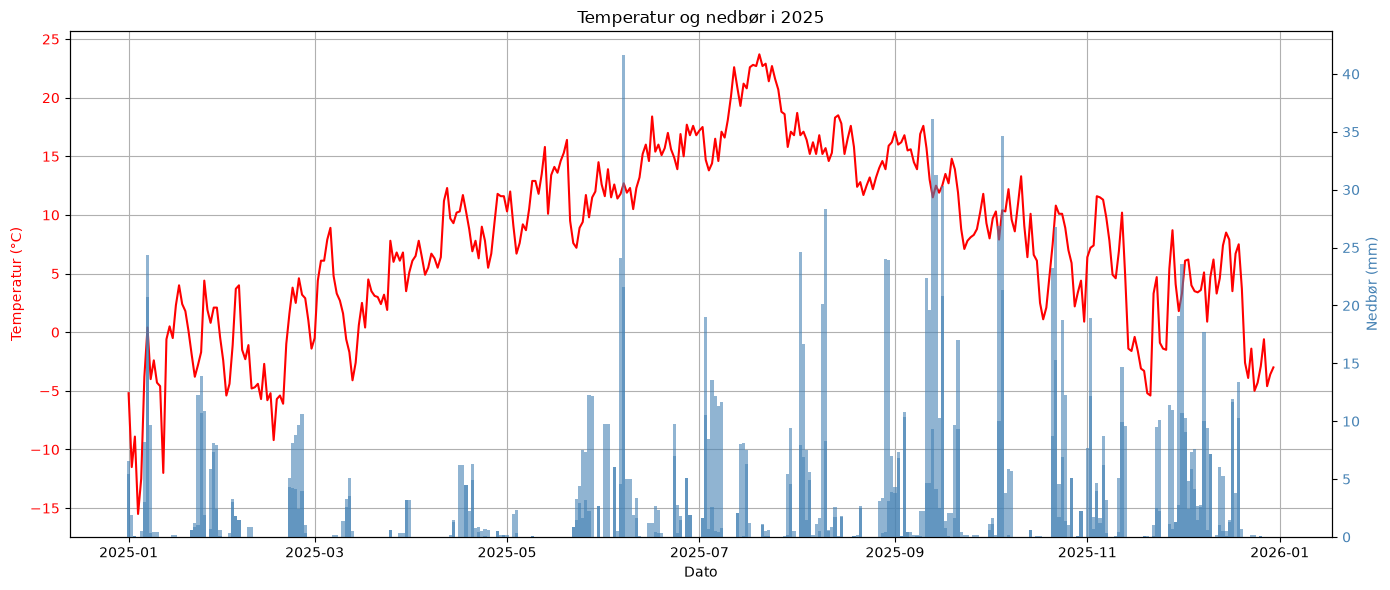

In [6]:

#Henter nedbørsdata
parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

r = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

json_data = r.json()

if r.status_code == 200:

    data = json_data["data"]

    rows = []

    for item in data:
        row = pd.DataFrame(item["observations"])
        row["referenceTime"] = item["referenceTime"]
        rows.append(row)

    df_precip = pd.concat(rows, ignore_index=True)

else:
    print(f"Feil! Statuskode: {r.status_code}")

# Klargjør nedbørsdata
df_precip["referenceTime"] = pd.to_datetime(df_precip["referenceTime"])

df_precip = df_precip[["referenceTime", "value"]]

df_precip.rename(
    columns={"value": "precipitation"},
    inplace = True
)

# Klargjør temperaturdata fra Task 1
df_temp = df[["referenceTime", "value"]].copy()

df_temp.rename(
    columns={"value": "temperature"},
    inplace=True
)

# Slå sammen temperatur og nedbør
weather = pd.merge(
    df_temp,
    df_precip,
    on="referenceTime",
    how="inner"
)

# Plot temperatur og nedbør i samme figur
fig, ax1 = plt.subplots(figsize=(14, 6))

# Temperatur som linje
ax1.plot(
    weather["referenceTime"],
    weather["temperature"],
    color="red",
    linewidth=1.5,
    label="Temperatur"
)

ax1.set_xlabel("Dato")
ax1.set_ylabel("Temperatur (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Nedbør som søyler
ax2 = ax1.twinx()

ax2.bar(
    weather["referenceTime"],
    weather["precipitation"],
    color="steelblue",
    alpha=0.6,
    width=1
)

ax2.set_ylabel("Nedbør (mm)", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")

plt.title("Temperatur og nedbør i 2025")
ax1.grid(True)

plt.tight_layout()
plt.show()


Task 3: Historical temperature data
Now you want to compare the 2025 temperatures to temperatures measured 100
years earlier.
Get these temperatures from the database.
Plot the new and the old temperatures in the same plot, still nicely formatted
Generate a summary table as for task 1, where you display data from both the new
and the old temperatures.


2025: 365 dager hentet (timeOffset PT0H)
1925: 365 dager hentet (timeOffset PT0H)


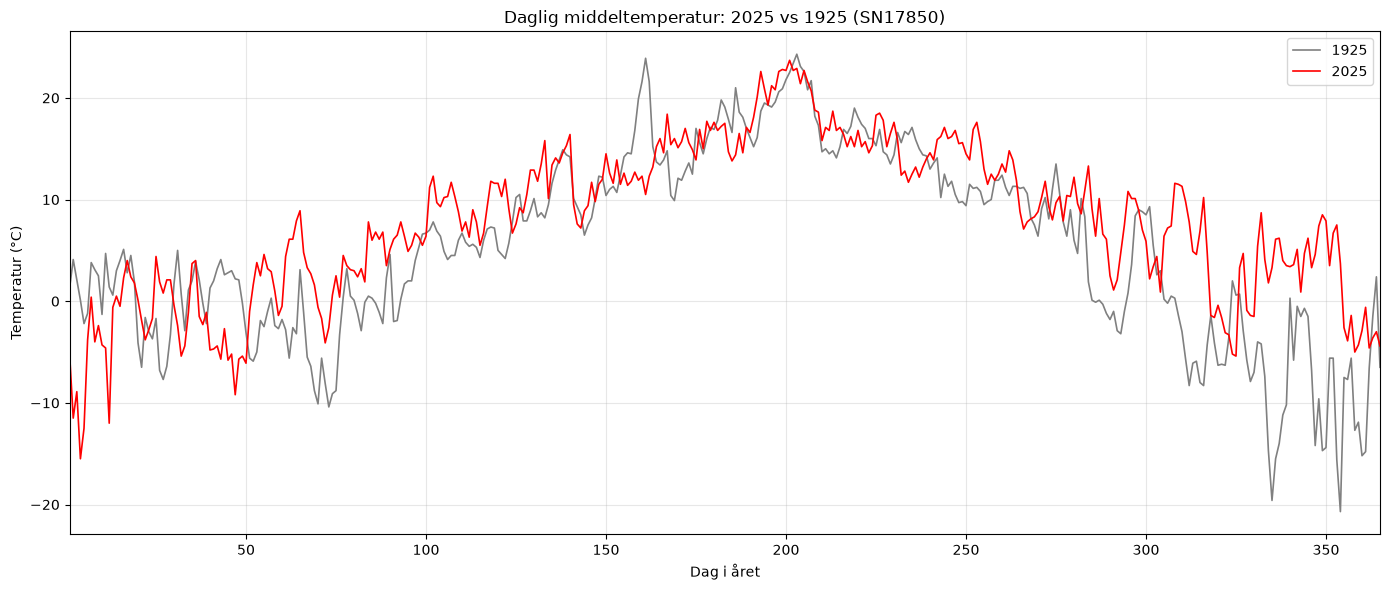


Sammendrag 1925 vs 2025:
Statistikk  1925 (°C)  2025 (°C)  Differanse (°C)
      Mean       5.28       7.87             2.59
    Median       5.30       8.30             3.00
       Min     -20.70     -15.50             5.20
       Max      24.30      23.70            -0.60


In [7]:
station_id = "SN17850"  # same station as task 1
element = "mean(air_temperature P1D)"
endpoint = "https://frost.met.no/observations/v0.jsonld"


def hent_temperatur(year):
    """Henter daglig middeltemperatur for ett år og returnerer en DataFrame."""
    r = requests.get(
        endpoint,
        params={
            "sources": station_id,
            "elements": element,
            "referencetime": f"{year}-01-01/{year + 1}-01-01",
        },
        auth=(client_id, ""),
    )
    if r.status_code != 200:
        print(f"Feil for {year}! Statuskode {r.status_code}")
        print(r.json()["error"]["reason"])
        raise SystemExit

    rows = []
    for item in r.json()["data"]:
        for obs in item["observations"]:
            rows.append({
                "date": item["referenceTime"][:10],
                "timeOffset": obs["timeOffset"],
                "value": obs["value"],
            })
    df = pd.DataFrame(rows)

    # Keep one series per day: PT0H if it exists, otherwise the most common offset
    offset = "PT0H" if "PT0H" in df["timeOffset"].values else df["timeOffset"].mode()[0]
    df = df[df["timeOffset"] == offset].copy()

    df["date"] = pd.to_datetime(df["date"])
    df["day"] = df["date"].dt.dayofyear
    print(f"{year}: {len(df)} dager hentet (timeOffset {offset})")
    return df[["day", "value"]].rename(columns={"value": f"temp_{year}"})


df2025 = hent_temperatur(2025)
df1925 = hent_temperatur(1925)

merged = pd.merge(df2025, df1925, on="day", how="inner")

# Plot
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(merged["day"], merged["temp_1925"], color="gray", linewidth=1.2, label="1925")
ax.plot(merged["day"], merged["temp_2025"], color="red", linewidth=1.2, label="2025")

ax.set_title(f"Daglig middeltemperatur: 2025 vs 1925 ({station_id})")
ax.set_xlabel("Dag i året")
ax.set_ylabel("Temperatur (°C)")
ax.set_xlim(1, 365)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Summary table (same statistics as task 1)
summary = pd.DataFrame({
    "Statistikk": ["Mean", "Median", "Min", "Max"],
    "1925 (°C)": [merged["temp_1925"].mean(), merged["temp_1925"].median(),
                  merged["temp_1925"].min(), merged["temp_1925"].max()],
    "2025 (°C)": [merged["temp_2025"].mean(), merged["temp_2025"].median(),
                  merged["temp_2025"].min(), merged["temp_2025"].max()],
})
summary["Differanse (°C)"] = summary["2025 (°C)"] - summary["1925 (°C)"]

print("\nSammendrag 1925 vs 2025:")
print(summary.round(2).to_string(index=False))



Task 4: Heatwaves
The next task is to look for heatwaves in Ås in 2025
In Norway a heatwave is defined as a consecutive period of five or more day where
the
max temperature is >= 27 degrees Celcius.
Note that you need max temperature here, not mean
Max temperature is coded as max(air_temperature P1D)
met.no article about heatwaves (only in Norwegian)
Write a function that count the number of heatwaves in a year.
The function should write a summary to a yml file, formatted as the example file
Write the function so that it will work with any station name/id and year



In [11]:
def heatwaves(name: str, id: str, reftime: str) -> None:
    count = 0
    heat_wave = []
    count_wave = 0
    year_ref = f"{reftime}-01-01/{reftime}-12-31"

    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
    'sources': id,
    'elements': 'max(air_temperature P1D)',
    'referencetime': year_ref,
    }
    
    with open("client_id.txt") as f:
        client_id = f.read().strip()

    rr = requests.get(endpoint, parameters, auth=(client_id, ''))
    json = rr.json()


    if rr.status_code == 200:
        data = json['data']
    else:
        print('Error! Returned status code %s' % rr.status_code)
        print('Message: %s' % json['error']['message'])
        print('Reason: %s' % json['error']['reason'])


    for item in data:
        item['referenceTime'] = item['referenceTime'].split("T")[0]
        time = datetime.strptime(item['referenceTime'], "%Y-%m-%d").date()
        temp_value = item['observations'][0]['value'] 
        if temp_value >= 27:
            if count == 0:
                first_date = time
            last_date = time
            count += 1
        elif count >= 5 and temp_value < 27:
            count = 0
            count_wave += 1
            wave = {"start": first_date,
                    "end": last_date,
                   }
            heat_wave.append(wave)
        else: 
            count = 0
    if count >= 5:
        count_wave += 1 
        wave = {"start": first_date,
                "end": last_date,
                }
        heat_wave.append(wave) 

    print(f"there have been {count_wave} heat waves")
    
    fname = Path("heatwave_summary.yml")


    with open(fname, "w") as f:
        f.write("dates:\n")
        for nr in heat_wave:
            f.write(f"- {nr['start']} - {nr['end']}\n")
        f.write(f"station_name: {name} \nstation_id: {id} \nyear: {reftime}")

heatwaves('Ås', 'SN17850', '2025')

there have been 1 heat waves


Task 5: Moving average temperature
Write a function that calculates the 7-day moving average for temperature
Use this function on the 2025 mean temperature you collected in task 1
Make a plot showing the moving average as a line and the daily temperature as
points

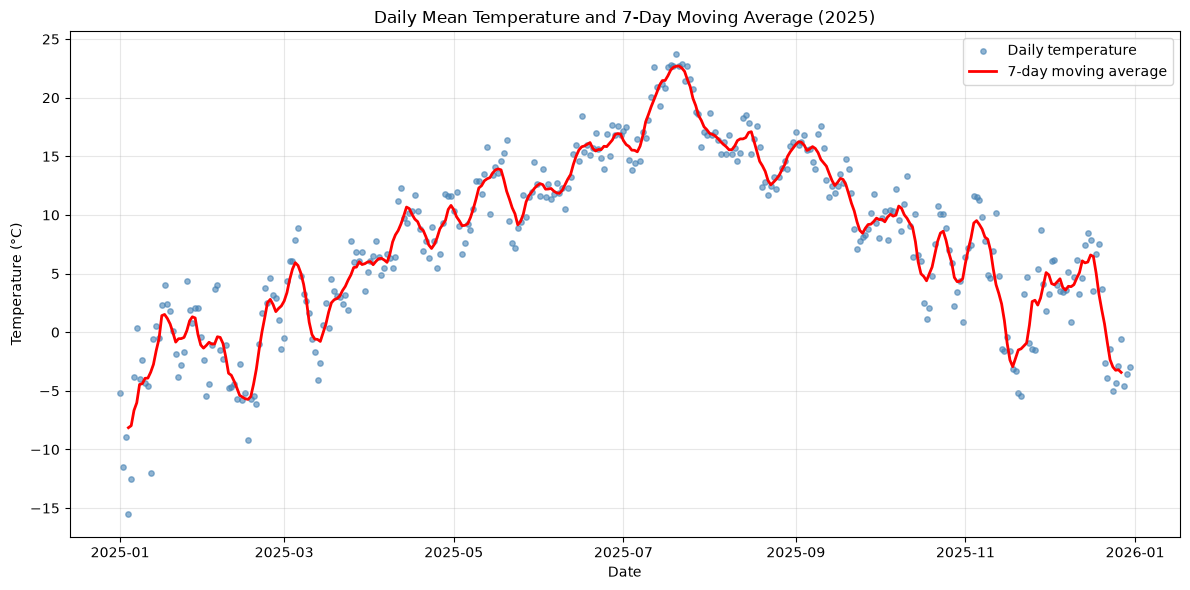

In [9]:
def moving_average_temperature(df, column="temperature", window=7):
    """
    Calculate moving average temperature.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing a temperature column
    column : str
        Name of the temperature column
    window : int
        Number of days in moving average

    Returns
    -------
    pandas.DataFrame
        Copy of df with a 'moving_average' column added
    """
    df = df.copy()
    df["moving_average"] = df[column].rolling(window=window, center=True).mean()
    return df


df_ma = moving_average_temperature(df_temp)

plt.figure(figsize=(12, 6))

# Daily temperatures as points
plt.scatter(
    df_ma["referenceTime"],
    df_ma["temperature"],
    color="steelblue",
    s=15,
    alpha=0.6,
    label="Daily temperature"
)

# Moving average as line
plt.plot(
    df_ma["referenceTime"],
    df_ma["moving_average"],
    color="red",
    linewidth=2,
    label="7-day moving average"
)

plt.title("Daily Mean Temperature and 7-Day Moving Average (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Kilde til inspirasjon til kode: https://frost.met.no/python_example.html

Har brukt generativ AI til å finpusse kode ut ifra utkast som jeg har gitt til den. (Se sammendrag på canvas)
